# Guía L2 — El índice sancocho · **Sesión 1: la receta como función**

**Cálculo Diferencial — Laboratorio computacional** · Universidad Nacional de Colombia, Sede Manizales

> Esta idea nació un domingo en Berlín, entre un döner y el recuerdo de una bullabesa. La historia completa está en la guía: este cuaderno es la sobremesa vuelta código.

**Uso en Colab:** guarden su copia (`Archivo → Guardar una copia en Drive`) y renómbrenla `L2_apellidos.ipynb`. Las celdas marcadas con ✏️ invitan a explorar o modificar; las marcadas con 🗣️ son para escribir conclusiones del equipo.

---
## ⏸️ Momento 1 — Predecir

Antes de ejecutar, respondan P1, P2 y P3 de la guía en papel: el costo del sancocho para seis en Manizales, si manda el espinazo o el resto de la olla, y si subió más la papa o el plátano. Foto al informe.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Precios mayoristas mensuales de SIPSA-DANE, congelados por el curso.
# El archivo .csv.gz se lee directamente: pandas reconoce la compresión.
RUTA = (
    "https://raw.githubusercontent.com/cmorregof/labs-calculo-2026-2/"
    "main/datos/sipsa_mensual.csv.gz"
)
df = pd.read_csv(RUTA)

print("Filas y columnas:", df.shape)
print(df.head(8))
df.tail() # Para hallar su dominio matemático en el punto 1

Filas y columnas: (666865, 5)
     fecha   ciudad             mercado                         producto  \
0  2013-01  Armenia  Armenia, Frigocafé          Carne de cerdo en canal   
1  2013-01  Armenia  Armenia, Frigocafé  Carne de cerdo, brazo con hueso   
2  2013-01  Armenia  Armenia, Frigocafé  Carne de cerdo, brazo sin hueso   
3  2013-01  Armenia  Armenia, Frigocafé   Carne de cerdo, cabeza de lomo   
4  2013-01  Armenia  Armenia, Frigocafé         Carne de cerdo, costilla   
5  2013-01  Armenia  Armenia, Frigocafé         Carne de cerdo, espinazo   
6  2013-01  Armenia  Armenia, Frigocafé   Carne de cerdo, lomo con hueso   
7  2013-01  Armenia  Armenia, Frigocafé   Carne de cerdo, lomo sin hueso   

   precio_kg  
0     6320.0  
1     8520.0  
2     9000.0  
3     9020.0  
4     9020.0  
5     6520.0  
6    11020.0  
7    12020.0  


,fecha,ciudad,mercado,producto,precio_kg
666860,2024-12,Yopal (Casanare),Yopal (Casanare),Tomate Riogrande,3750.0
666861,2024-12,Yopal (Casanare),Yopal (Casanare),Tomate de árbol,2950.0
666862,2024-12,Yopal (Casanare),Yopal (Casanare),Uva Isabela,4680.0
666863,2024-12,Yopal (Casanare),Yopal (Casanare),Yuca llanera,1354.0
666864,2024-12,Yopal (Casanare),Yopal (Casanare),Zanahoria,2552.0


---
## 1 · El ritual, ya sin niñera

En L1 lo hicimos juntos; hoy es de ustedes. El objetivo es decidir qué valores acepta cada columna, buscar valores ilegales y entender el alcance del congelado. Después, busquen los nombres oficiales de los ingredientes: los datos no saben cómo los llamamos en la casa.

🗣️ Escriban como comentario sus decisiones sobre los valores faltantes, precios no positivos y filas repetidas. ¿Una fila por `(fecha, mercado, producto)` es lo esperado?

In [ ]:
# ✏️ Ejercicio 1 — Completen la auditoría y dejen sus decisiones en comentarios.
print("Productos distintos:", df["producto"].nunique())
print("Ciudades:", df["ciudad"].nunique())
print("Meses: de", df["fecha"].min(), "a", df["fecha"].max())
print("\nTipos de dato:\n", df.dtypes)
print("\nValores faltantes por columna:\n", df.isna().sum())
print("\nPrecios medios no positivos:", (df["precio_kg"] <= 0).sum())
print("Filas repetidas por fecha, mercado y producto:",
      df.duplicated(["fecha", "mercado", "producto"]).sum())
# Decisiones:
# Faltantes: Ninguna columna tiene valores faltantes, así que no cambiamos nada
# Precios no positivos: 0 filas con precio_kg <= 0. Todos los precios son > 0, por lo que son válidos
# Filas repetidas: 0 duplicadas, cada combinación (fecha, mercado, producto) aparece una sola vez, por lo que si es esperado y se cumple

# ¿Qué dominio matemático le asignan a fecha, ciudad, mercado, producto y precio_kg?
# Dominios:
# Fecha: meses entre 2013-01 y 2024-12 (conjunto finito y ordenado).
# Ciudad (con 71 valores distintos), mercado (con n valores distintos), producto (con 385 valores distintos): conjuntos finitos de categorías, sin orden.
# Precio_kg: números reales estrictamente positivos (+R).

Productos distintos: 385
Ciudades: 71
Meses: de 2013-01 a 2024-12

Tipos de dato:
 fecha         object
ciudad        object
mercado       object
producto      object
precio_kg    float64
dtype: object

Valores faltantes por columna:
 fecha        0
ciudad       0
mercado      0
producto     0
precio_kg    0
dtype: int64

Precios medios no positivos: 0
Filas repetidas por fecha, mercado y producto: 0


In [ ]:
# ✏️ Ejercicio 2 — Cambien `busca` e iteren.
# Encuentren los nombres oficiales de espinazo, yuca, papa, mazorca y plátano verde.
# Luego restrinjan la búsqueda a Manizales: no todas las variedades se venden allí.
busca = "espinazo"
coincidencias = df.loc[
    df["producto"].str.contains(busca, case=False, na=False),
    ["ciudad", "mercado", "producto"],
]
print("Espinazo:")
print(coincidencias["producto"].drop_duplicates().to_list())
busca2 = "yuca"
coincidencias = df.loc[
    df["producto"].str.contains(busca2, case=False, na=False),
    ["ciudad", "mercado", "producto"],
]
print("Yuca:")
print(coincidencias["producto"].drop_duplicates().to_list())
busca3 = "papa"
coincidencias = df.loc[
    df["producto"].str.contains(busca3, case=False, na=False),
    ["ciudad", "mercado", "producto"],
]
print("Papa:")
print(coincidencias["producto"].drop_duplicates().to_list())
busca4 = "mazorca"
coincidencias = df.loc[
    df["producto"].str.contains(busca4, case=False, na=False),
    ["ciudad", "mercado", "producto"],
]
print("Mazorca:")
print(coincidencias["producto"].drop_duplicates().to_list())
busca5 = "plátano"
coincidencias = df.loc[
    df["producto"].str.contains(busca5, case=False, na=False),
    ["ciudad", "mercado", "producto"],
]
print("Plátano verde:")
print(coincidencias["producto"].drop_duplicates().to_list())
# Pista para Manizales:
print("Solo en manizales:")
print("Espinazo:")
print(df.loc[(df["ciudad"] == "Manizales") & df["producto"].str.contains(busca, case=False, na=False), "producto"].unique())
print("Yuca:")
print(df.loc[(df["ciudad"] == "Manizales") & df["producto"].str.contains(busca2, case=False, na=False), "producto"].unique())
print("Papa:")
print(df.loc[(df["ciudad"] == "Manizales") & df["producto"].str.contains(busca3, case=False, na=False), "producto"].unique())
print("Mazorca:")
print(df.loc[(df["ciudad"] == "Manizales") & df["producto"].str.contains(busca4, case=False, na=False), "producto"].unique())
print("Plátano verde:")
print(df.loc[(df["ciudad"] == "Manizales") & df["producto"].str.contains(busca5, case=False, na=False), "producto"].unique())

Espinazo:
['Carne de cerdo, espinazo']
Yuca:
['Yuca ICA', 'Yuca criolla', 'Yuca llanera', 'Yuca chirosa']
Papa:
['Carne de cerdo, tocino papada', 'Papa R-12 negra', 'Papa criolla limpia', 'Papa parda pastusa', 'Papa suprema', 'Papaya Maradol', 'Papa R-12 roja', 'Papa criolla sucia', 'Papa única', 'Papa sabanera', 'Papaya hawaiana', 'Papa frita', 'Papa ICA-Huila', 'Papaya melona', 'Papaya redonda', 'Papa capira', 'Papa Morasurco', 'Papa criolla para lavar', 'Papa nevada', 'Papa roja peruana', 'Papa tocana', 'Papa Puracé', 'Papa San Félix', 'Papa rubí', 'Papa tocarreña', 'Papa superior', 'Papa Betina', 'Papaya tainung', 'Papaya Paulina']
Mazorca:
['Chócolo mazorca']
Plátano verde:
['Plátano guineo', 'Plátano hartón maduro', 'Plátano hartón verde', 'Plátano dominico hartón verde', 'Plátano hartón verde llanero', 'Plátano hartón verde venezolano', 'Plátano dominico hartón maduro', 'Plátano comino', 'Plátano dominico verde', 'Plátano hartón verde ecuatoriano', 'Plátano hartón verde Eje Cafe

---
## 2 · La receta en código

La receta oficial es para seis personas. Cada valor está en kilogramos, que es la unidad del mercado: 1,5 kg de espinazo, 1 kg de yuca, 1 kg de papa, 0,9 kg de mazorca y 1,4 kg de plátano. Traducir de unidades de cocina a kilogramos también es una función.

In [ ]:
RECETA = {
    "Carne de cerdo, espinazo":       1.5,
    "Yuca ICA":                       1.0,
    "Papa capira":                    1.0,
    "Chócolo mazorca":                0.9,
    "Plátano dominico hartón verde":  1.4,
}
print("Ingredientes:", len(RECETA), "| Kilos totales:", sum(RECETA.values()))

# ✏️ Confirmen que cada nombre existe para Manizales antes de seguir.
# Buscando en las listas dadas anteriormente, pudimos encontrar todos los nombres de la receta repartidos en las diferentes listas

Ingredientes: 5 | Kilos totales: 5.8


---
## 3 · El pipeline, pieza por pieza

Estas cuatro funciones son puras: reciben una tabla y sus parámetros, y devuelven una tabla o un número. No dependen de `df`, `RECETA` ni ninguna otra variable externa. Lean cada contrato, prueben cada función por separado y luego sigan el dato a través de la composición.

In [ ]:
def filtrar_ciudad(tabla, ciudad):
    """tabla → tabla: conserva únicamente las filas de una ciudad."""
    return tabla.loc[tabla["ciudad"] == ciudad].copy()

def filtrar_mes(tabla, fecha):
    """tabla → tabla: conserva únicamente el mes AAAA-MM indicado."""
    return tabla.loc[tabla["fecha"] == fecha].copy()

def filtrar_productos(tabla, receta):
    """tabla → tabla: conserva los productos que aparecen en la receta."""
    return tabla.loc[tabla["producto"].isin(receta)].copy()

def costear(tabla, receta):
    """tabla → número: suma kilos × precio_kg de cada ingrediente."""
    precios = tabla.groupby("producto")["precio_kg"].mean()
    faltantes = [producto for producto in receta if producto not in precios]
    if faltantes:
        raise ValueError(f"Faltan ingredientes: {faltantes}")
    return sum(kilos * precios[producto] for producto, kilos in receta.items())

# ✏️ ¿Por qué `.isin(receta)` sirve para varios productos y `== receta` no?
# Porque al aplicar ".isin(receta)" permite comprobar dentro de una lista, coincidencias o valores mulitples,
# en cambio el "== receta" devuelve un valor exacto dentro de la lista.

# ¿En qué situación habría varias filas del mismo ingrediente y por qué usamos `mean`?
# Donde ese mismo ingrediente se tenga que promediar varios productos con el mismo ingrediente, colapsando esas filas,
# aqui es donde el ".mean" entra aplicar el colapso de ese mismo ingrediente.


print("1. Probando filtrar_ciudad:")
df_manizales = filtrar_ciudad(df, "Manizales")
print(df_manizales.head(2))

print("2. Probando filtrar_mes:")
df_mes = filtrar_mes(df_manizales, "2013-01")
print(df_mes.head(2))

print("3. Probando filtrar_productos:")
df_receta = filtrar_productos(df_mes, RECETA)
print(df_receta.head(2))

print("4. Probando costear:")
costo = costear(df_receta, RECETA)
print(f"Costo total calculado: ${costo:,.2f}")

1. Probando filtrar_ciudad:
        fecha     ciudad                     mercado               producto  \
2161  2013-01  Manizales  Manizales, Centro Galerías  Aceite vegetal mezcla   
2162  2013-01  Manizales  Manizales, Centro Galerías         Aguacate común   

      precio_kg  
2161     4416.0  
2162     2111.0  
2. Probando filtrar_mes:
        fecha     ciudad                     mercado               producto  \
2161  2013-01  Manizales  Manizales, Centro Galerías  Aceite vegetal mezcla   
2162  2013-01  Manizales  Manizales, Centro Galerías         Aguacate común   

      precio_kg  
2161     4416.0  
2162     2111.0  
3. Probando filtrar_productos:
        fecha     ciudad                     mercado  \
2180  2013-01  Manizales  Manizales, Centro Galerías   
2193  2013-01  Manizales  Manizales, Centro Galerías   

                      producto  precio_kg  
2180  Carne de cerdo, espinazo     7000.0  
2193           Chócolo mazorca      541.0  
4. Probando costear:
Costo tota

In [ ]:
# Una función que fabrica la función compuesta.
def componer(*funciones):
    def compuesta(x):
        for funcion in funciones:
            x = funcion(x)
        return x
    return compuesta

CIUDAD = "Manizales"
MES = df.loc[df["ciudad"] == CIUDAD, "fecha"].max()

costo_sancocho = componer(
    lambda tabla: filtrar_ciudad(tabla, CIUDAD),
    lambda tabla: filtrar_mes(tabla, MES),
    lambda tabla: filtrar_productos(tabla, RECETA),
    lambda tabla: costear(tabla, RECETA),
)

print(f"Mercado del sancocho en {CIUDAD}, {MES}: ${costo_sancocho(df):,.0f}")

# ✏️ Dibujen el recorrido de `df` por las cuatro funciones.
# df (todas las ciudades, fechas y productos)
#
#   filtrar_ciudad(tabla, "Manizales")
# solo filas de Manizales
#
#   filtrar_mes(tabla, MES)
# solo Manizales en el último mes (MES = la fecha máxima)
#
#   filtrar_productos(tabla, RECETA)
# solo las filas de los 5 ingredientes de la receta
#
#   costear(tabla, RECETA)
# un número: suma de (precio_kg × kilos) de cada ingrediente

# ¿Por qué una lambda permite fijar ciudad, mes y receta sin romper la pureza de las funciones?
# La lambda fija ciudad, mes y receta como constantes capturadas, convirtiendo funciones de varios argumentos en funciones de uno solo.
# Sigue siendo pura: mismo df -> mismo resultado, y no modifica df ni ninguna variable global.

Mercado del sancocho en Manizales, 2024-12: $28,634


🗣️ **Confronten P1:** ¿quién tuvo el mejor ojo de mercado? Los datos son precios mayoristas de una central de abastos: ¿el mercado de la esquina cobraría más o menos y por qué?

Diana fue la que mejor ojo de mercado tuvo, todos estabamos de acuerdo con 2 preguntas pero en la P3 tuvimos un punto de vista diferente, ella creía que el plátano subió más de precio, y el resto del equipo creíamos que la papá, al final resultó ser el plátano.

 Desde la experiencia de cada uno de los integrantes del grupo, concluimos que en las tiendas locales o tienditas de la esquina cobrarian mas por un producto, ya que estas acuden directamente a las centrales de abasto. en dichas centrales importan una mayor cantidad de unidades por producto y las adquieren directamente del productor, eso hace que el costo de su distribución no se vea tan afectada. En las tiendas locales pasan por mas distribuidores, elevando los precios.

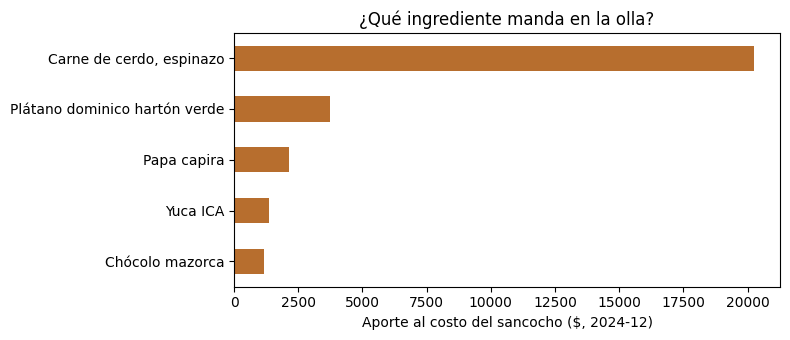

El espinazo aporta $20,250 de $28,634: 71% de la olla.
------------------------------------------------------------------------------------------------
Papa capira (2013-01): $506.0/kg
Papa capira (2024-12): $2,133.0/kg
Plátano dominico hartón verde (2013-01): $570.0/kg
Plátano dominico hartón verde (2024-12): $2,663.0/kg


In [ ]:
# ¿Qué ingrediente manda? Confronten P2 con los aportes al costo.
# El espinazo manda sobre los otros alimentos aún si los enfrentamos a él contra todos.
mes_tabla = filtrar_productos(
    filtrar_mes(filtrar_ciudad(df, CIUDAD), MES), RECETA
)
precios_mes = mes_tabla.groupby("producto")["precio_kg"].mean()
aportes = pd.Series({
    producto: kilos * precios_mes[producto]
    for producto, kilos in RECETA.items()
}).sort_values()

ax = aportes.plot.barh(figsize=(8, 3.5), color="#B76E2E")
ax.set_xlabel(f"Aporte al costo del sancocho ($, {MES})")
ax.set_title("¿Qué ingrediente manda en la olla?")
plt.tight_layout()
plt.show()

total = aportes.sum()
espinazo = aportes["Carne de cerdo, espinazo"]
print(f"El espinazo aporta ${espinazo:,.0f} de ${total:,.0f}: {100 * espinazo / total:.0f}% de la olla.")
print("------------------------------------------------------------------------------------------------")

# ✏️ Para P3, cambien la receta a solo papa y plátano; comparen el primer y último mes.
receta = {
    "Papa capira": 1.0,
    "Plátano dominico hartón verde": 1.4
}

ciudad_miz = filtrar_ciudad(df, "Manizales")
mes_inicial = "2013-01"
mes_final = "2024-12"

tabla_ini = filtrar_productos(filtrar_mes(ciudad_miz, mes_inicial), receta)
precios_ini = tabla_ini.groupby("producto")["precio_kg"].mean()

tabla_fin = filtrar_productos(filtrar_mes(ciudad_miz, mes_final), receta)
precios_fin = tabla_fin.groupby("producto")["precio_kg"].mean()

for prod in receta:
    print(f"{prod} ({mes_inicial}): ${precios_ini[prod]:,.1f}/kg")
    print(f"{prod} ({mes_final}): ${precios_fin[prod]:,.1f}/kg")

---
## 4 · Momento 3 — Explicar

🗣️ Media página del equipo: confronten P1 y P2, expliquen cómo decidieron los nombres oficiales y completen la frase: **«Un pipeline es una composición de funciones porque toma la salida de una función y la usa directamente como la entrada de la siguiente.»**

En P1 y P2 estuvimos muy cerca a los valores exactos, de por si estabamos en lo correcto pero lo que faltaba fue examinar con exactitud, como con porcentajes, como lo hizo la comparación del espinazo con el resto de ingredientes, y el precio del sancocho en nuestra predicción es muy similar al de este cuaderno (sumando los valores a mano). Los nombres oficiales no los decidimos como tal, seguímos tal cuál como nos lo iba mostrando el cuaderno de esta sesión.

---
## 🤖 Protocolo de IA

Las reglas de siempre siguen vigentes: intento propio, la IA no es autoridad final y todo uso va en la bitácora individual. Para la cacería estrella pregunten a una IA, sin contexto: *«¿cuánto cuesta hacer un sancocho para seis personas en Colombia?»*. Guarden la respuesta y la fecha. En la sesión 2 la compararán con el índice construido sobre datos oficiales.

**Próxima sesión:** el índice en el tiempo, los picos históricos, el duelo de ciudades, la conmutatividad y la unidad sancocho. Averigüen antes qué ingredientes lleva el plato de su casa.